# Wadi Ghadir gravity – cross-section, forward modelling and inversion with pyGIMLi and SimPEG

**Wadi Ghadir, Eastern Desert, Egypt · residual complete Bouguer anomaly**

**Written by Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook continues notebook 03. It starts from the gridded complete Bouguer anomaly and its residual
(`outputs/open_source/Wadi_Ghadir_OpenSource_Grids.nc`) and goes on to modelling:

| Step | Tool | Content |
|---:|---|---|
| 1 | xarray | Load the grids and choose a cross-section A–B |
| 2 | xarray, Copernicus DEM | Residual anomaly and topography along the section |
| 3 | **pyGIMLi** | 2-D forward model of simple bodies (Talwani-type line integrals) |
| 4 | **pyGIMLi** | Depth-weighted 2-D density inversion of the section, with an L-curve |
| 5 | **SimPEG** | 3-D inversion of the residual grid (integral formulation, Choclo kernels) |
| 6 | | The pyGIMLi section and the SimPEG model along the same line |
| 7 | | Export of profiles, models and figures to `outputs/modelling/` |

**Read the results with care.** A gravity anomaly can be explained by infinitely many density models. The
inversions below give the simplest models that fit the data under the chosen depth weighting and regularisation.
They show where mass excess or deficit is likely, not the true shape of geological bodies. The 2-D model assumes
the structures continue far to both sides of the section; the 3-D model does not.

As in the other notebooks, every step has **✏️ PARAMETERS**, **▶ PROCESSING** and **📊 RESULT** cells.

## 0  Set-up

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 82}}
import json
import logging
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.path import Path

REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)            # pyGIMLi and SimPEG progress messages

import discretize
import pygimli as pg
import pyproj
import simpeg
from discretize import TensorMesh
from pygimli.physics.gravimetry import GravityModelling2D, depthWeighting, solveGravimetry
from simpeg import data, data_misfit, directives, inverse_problem, inversion, maps, optimization, regularization
from simpeg.potential_fields import gravity

from wghadir.common import geodata, mapping
from wghadir.gravity import settings

GRID_FILE = os.path.join(REPO, "outputs", "open_source", "Wadi_Ghadir_OpenSource_Grids.nc")
OUT_DIR = os.path.join(REPO, "outputs", "modelling")
os.makedirs(OUT_DIR, exist_ok=True)
UTM = pyproj.Proj("EPSG:32636")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
DENS_CMAP = "RdBu_r"
print("pyGIMLi", pg.__version__, "| SimPEG", simpeg.__version__, "| discretize", discretize.__version__)

No module named 'pyvista'.
You need to install this optional dependency to properly visualize 3D data.
No module named 'trame'.
You need to install this optional dependency to use interactive 3D visualizations within Jupyter notebooks.
No module named 'pyvista'.
You need to install this optional dependency to properly visualize 3D data.
No module named 'pyvista'.
You need to install this optional dependency to properly visualize 3D data.
pyGIMLi 1.6.1 | SimPEG 0.25.2 | discretize 0.12.0


## 1  Grids and the cross-section

The grids come from notebook 03 (run it first if the file is missing). The residual anomaly, i.e. the complete
Bouguer anomaly minus its upward continuation, holds the shallow sources that modelling can resolve. The section
A–B is given in longitude/latitude. The default crosses the low in the south-west and the central high.

In [2]:
# ✏️ PARAMETERS – edit and re-run from here
A_LONLAT = (34.7448, 24.7058)        # start of the section (lon, lat)
B_LONLAT = (34.9490, 24.8117)        # end of the section
SAMPLE_M = 250.0                     # spacing of the profile points
FIELD = "residual"                   # "residual" or "complete_bouguer"

In [3]:
# ▶ PROCESSING
grids = xr.open_dataset(GRID_FILE)
(ea, na), (eb, nb) = UTM(*A_LONLAT), UTM(*B_LONLAT)
L = np.hypot(eb - ea, nb - na)
dist = np.arange(0.0, L + 1e-6, SAMPLE_M)
pe, pn = ea + dist / L * (eb - ea), na + dist / L * (nb - na)
at = dict(easting=xr.DataArray(pe, dims="p"), northing=xr.DataArray(pn, dims="p"))
inside = grids["data_mask"].astype(float).interp(**at).values > 0.5
print(f"section {L / 1000:.1f} km, {len(dist)} points, {inside.sum()} within the data area; grid attributes: {dict(grids.attrs)}")

section 23.8 km, 96 points, 96 within the data area; grid attributes: {'crs': 'EPSG:32636', 'author': 'Dr. Mohamed Sobh, LIAG', 'tide': 'eterna', 'product': 'disturbance', 'terrain': 'zoned', 'density': np.float64(2.67), 'gridding': 'spline'}


[None,
 Text(0.5, 0, 'easting [km, UTM 36N]'),
 Text(0, 0.5, 'northing [km]'),
 Text(0.5, 1.0, 'residual and section A–B')]

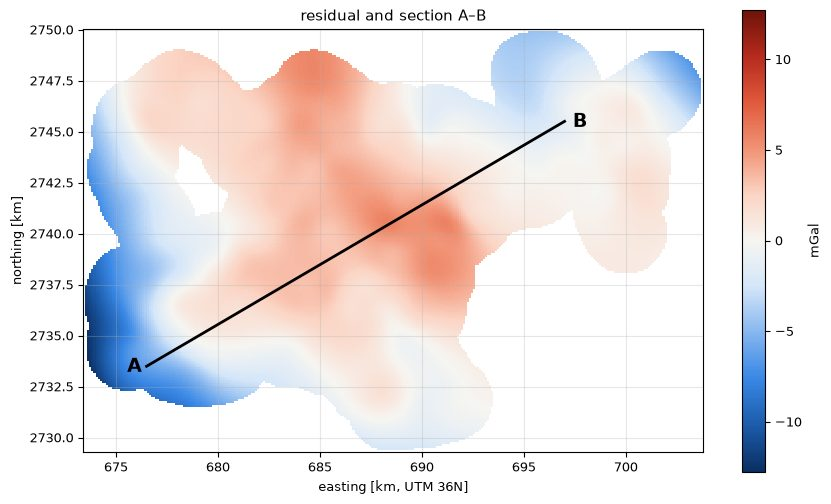

In [4]:
# 📊 RESULT
fig, ax = plt.subplots(figsize=(10, 6))
v = grids[FIELD].where(grids["data_mask"])
m = ax.pcolormesh(grids.easting / 1000, grids.northing / 1000, v, cmap=mapping.ANOM, shading="auto",
                  vmin=-np.nanmax(np.abs(v)), vmax=np.nanmax(np.abs(v)))
ax.plot([ea / 1000, eb / 1000], [na / 1000, nb / 1000], "k-", lw=2)
ax.annotate("A", (ea / 1000, na / 1000), fontsize=14, fontweight="bold", xytext=(-14, -4), textcoords="offset points")
ax.annotate("B", (eb / 1000, nb / 1000), fontsize=14, fontweight="bold", xytext=(6, -4), textcoords="offset points")
plt.colorbar(m, ax=ax, label="mGal")
ax.set(aspect="equal", xlabel="easting [km, UTM 36N]", ylabel="northing [km]", title=f"{FIELD.replace('_', ' ')} and section A–B")

## 2  Anomaly and topography along the section

The anomaly is interpolated from the grid; the topography is sampled from the Copernicus GLO-30 DEM. For modelling,
the mean of the residual is removed (`REMOVE_LINEAR` also removes a linear trend), because a residual anomaly has no
absolute level.

In [5]:
# ✏️ PARAMETERS – edit and re-run from here
REMOVE_LINEAR = False

In [6]:
# ▶ PROCESSING
anom = grids[FIELD].interp(**at).values
dem = geodata.Grid(os.path.join(REPO, "data", "external", settings.DEM_FILE))
lon_p, lat_p = UTM(pe, pn, inverse=True)
topo = dem.sample(lon_p, lat_p)
keep = inside & np.isfinite(anom)
x = dist[keep]                                   # distance along the section [m]
d_obs = anom[keep] - np.mean(anom[keep])
if REMOVE_LINEAR:
    d_obs = d_obs - np.polyval(np.polyfit(x, d_obs, 1), x)
section = pd.DataFrame({"distance_m": x, "easting": pe[keep], "northing": pn[keep], "lon": lon_p[keep], "lat": lat_p[keep],
                        "topography_m": topo[keep], "anomaly_mGal": anom[keep], "data_mGal": d_obs})
print(f"{len(section)} points; data range {d_obs.min():.2f} … {d_obs.max():.2f} mGal")

96 points; data range -7.73 … 4.26 mGal


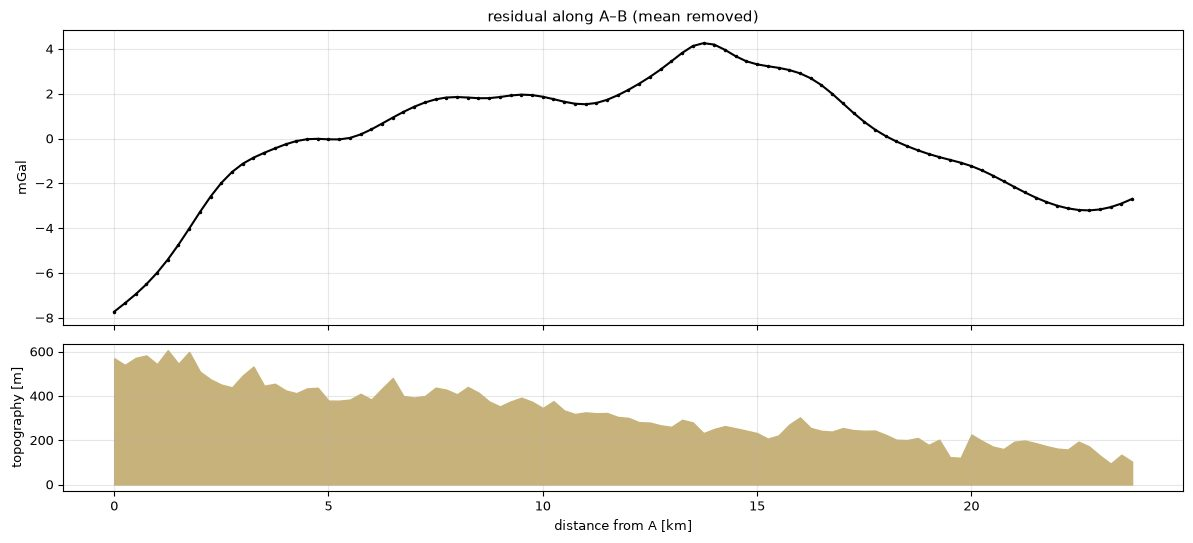

In [7]:
# 📊 RESULT
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(x / 1000, d_obs, "k.-", ms=3)
axes[0].set(ylabel="mGal", title=f"{FIELD.replace('_', ' ')} along A–B (mean removed)")
axes[1].fill_between(x / 1000, 0, section["topography_m"], color="#c8b27c")
axes[1].set(xlabel="distance from A [km]", ylabel="topography [m]")
plt.tight_layout()

## 3  Forward modelling with pyGIMLi

A hypothesis is drawn as polygons in the section (distance and depth in km, density contrast in kg/m³). Their
gravity is computed with pyGIMLi (`solveGravimetry`, line integrals over 2-D cells) and compared with the data.
Change the polygons or densities and re-run to test other ideas. Step 4 lets the data choose a model instead.

In [8]:
# ✏️ PARAMETERS – edit and re-run from here
BODIES = [   # vertices (distance km, depth km), density contrast kg/m³ – a hypothesis to test
    dict(name="light basin fill", drho=-120, xy=[(-3.0, 0.0), (4.5, 0.0), (3.5, 1.2), (-3.0, 1.4)]),
    dict(name="dense block", drho=90, xy=[(6.0, 1.0), (17.0, 1.0), (17.0, 2.4), (6.0, 2.4)]),
    dict(name="light cover", drho=-80, xy=[(19.0, 0.0), (25.0, 0.0), (25.0, 0.8), (19.0, 0.8)]),
]
CELL_X_M, PAD_M = 250.0, 6000.0           # model mesh: cell width and padding beyond A and B
Z_EDGES_M = np.arange(0.0, 6001.0, 200.0)   # uniform layers (changing cell sizes print bands into the inversion)

In [9]:
# ▶ PROCESSING
xe = np.arange(x.min() - PAD_M, x.max() + PAD_M + 1, CELL_X_M)
mesh2d = pg.createGrid(xe, -Z_EDGES_M[::-1])                 # pyGIMLi: y is up, so depths are negative
cc = np.array([[c.center().x(), c.center().y()] for c in mesh2d.cells()])
rho_fwd = np.zeros(mesh2d.cellCount())
for b in BODIES:
    poly = Path([(px * 1000, -pz * 1000) for px, pz in b["xy"]])
    rho_fwd[poly.contains_points(cc)] = b["drho"]
sensors = np.column_stack([x, np.full_like(x, 1.0)])           # 1 m above a flat datum
fop = GravityModelling2D(points=sensors, mesh=mesh2d)
d_fwd = np.asarray(fop.response(pg.Vector(rho_fwd)))
d_fwd -= d_fwd.mean()
print(f"forward model: rms misfit {np.sqrt(np.mean((d_fwd - d_obs) ** 2)):.2f} mGal (data rms {np.sqrt(np.mean(d_obs ** 2)):.2f})")

forward model: rms misfit 1.35 mGal (data rms 2.76)


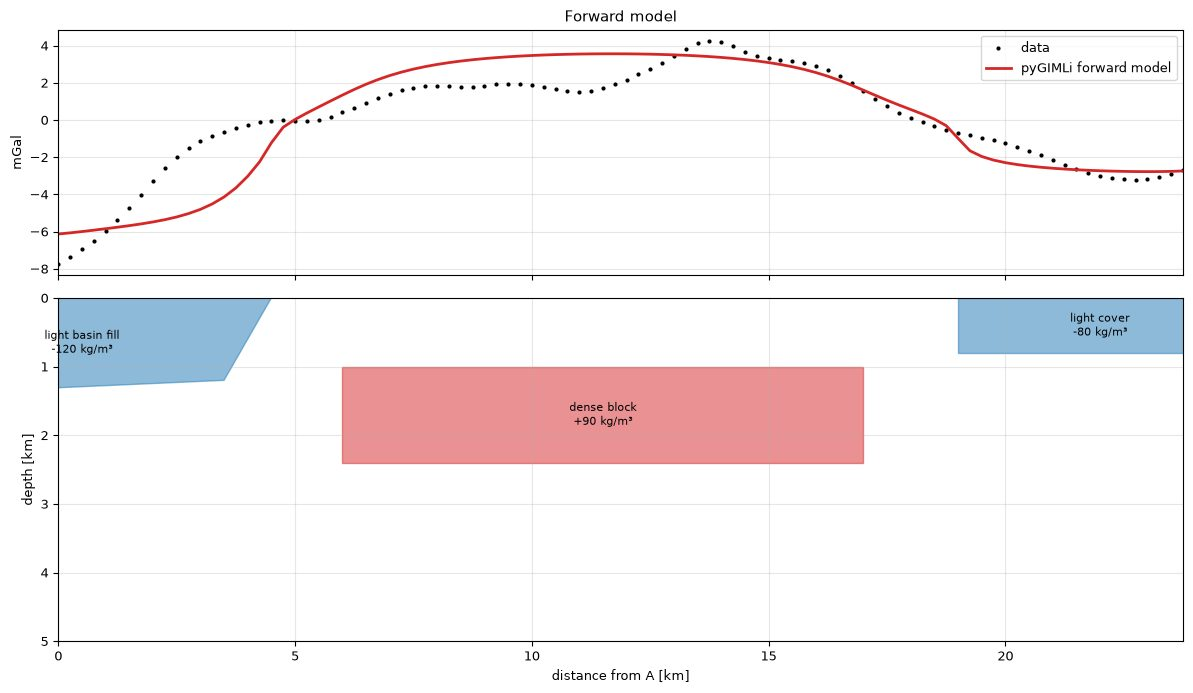

In [10]:
# 📊 RESULT
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
axes[0].plot(x / 1000, d_obs, "k.", ms=4, label="data")
axes[0].plot(x / 1000, d_fwd, "-", color="C3", lw=2, label="pyGIMLi forward model")
axes[0].set(ylabel="mGal", title="Forward model")
axes[0].legend()
for b in BODIES:
    xs, zs = zip(*(b["xy"] + [b["xy"][0]]))
    axes[1].fill(xs, zs, color="C3" if b["drho"] > 0 else "C0", alpha=0.5)
    axes[1].text(np.mean(xs[:-1]), np.mean(zs[:-1]), f"{b['name']}\n{b['drho']:+d} kg/m³", ha="center", va="center", fontsize=8)
axes[1].set(ylim=(5, 0), xlabel="distance from A [km]", ylabel="depth [km]", xlim=(x.min() / 1000, x.max() / 1000))
plt.tight_layout()

## 4  2-D inversion with pyGIMLi

`pygimli.Inversion` finds the smallest density model on the 2-D mesh that fits the data to the given error
(regularisation `cType=0`). Gravity has no intrinsic depth resolution: without help, all mass would be put just
below the surface. A Li & Oldenburg depth weighting w(z) = (1 + z/z₀)^(−p) (`depthWeighting`) counteracts the
decay of the kernels; for a 2-D section the sensitivity of a cell falls off as z^(−1/2), hence p = 0.5.
The L-curve shows misfit against model size for several regularisation strengths λ. With `LAMBDA = "auto"`
the λ whose χ² is closest to 1 is used, that is, the data are fitted to their error and no further.

In [11]:
# ✏️ PARAMETERS – edit and re-run from here
LAMBDA = "auto"                        # a number, or "auto": the λ of the L-curve whose χ² is closest to 1
ERROR_MGAL = 0.30                      # data error [mGal]: gridding error plus the 2-D assumption on a 3-D field
LCURVE_LAMBDAS = (1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1)
DW_Z0_M, DW_POWER = 500.0, 0.5         # depth weighting (1 + z/z0)^-p; p = 0 switches it off
CTYPE = 0                              # 0: smallest model, 1: smoothest model (try it: very different picture!)

In [12]:
# ▶ PROCESSING
def invert2d(lam):
    fop = GravityModelling2D(points=sensors, mesh=mesh2d)
    inv = pg.Inversion(fop=fop, verbose=False)
    inv.setRegularization(cType=CTYPE, trans="lin")
    inv.modelTrans = pg.trans.Trans()          # linear: density contrasts may be negative
    inv.dataTrans = pg.trans.Trans()
    if DW_POWER > 0:
        inv.setConstraintWeights(depthWeighting(mesh2d, z0=DW_Z0_M, power=DW_POWER, cell=(CTYPE == 0)))
    m = inv.run(d_obs, absoluteError=ERROR_MGAL, lam=lam, startModel=0.0, maxIter=10)
    return np.asarray(m), np.asarray(inv.response), inv.chi2()

tic = time.time()
lcurve = []
for lam in LCURVE_LAMBDAS:
    m, r, chi2 = invert2d(lam)
    lcurve.append(dict(lam=lam, chi2=chi2, rms_mgal=np.sqrt(np.mean((r - d_obs) ** 2)), model_norm=np.sqrt(np.mean(m ** 2))))
lcurve = pd.DataFrame(lcurve)
if LAMBDA == "auto":
    LAMBDA = float(lcurve.iloc[(np.log(lcurve["chi2"])).abs().argmin()]["lam"])
rho_pg, d_pg, chi2_pg = invert2d(LAMBDA)
print(f"pyGIMLi: λ = {LAMBDA}, χ² = {chi2_pg:.2f}, rms {np.sqrt(np.mean((d_pg - d_obs) ** 2)):.3f} mGal, "
      f"density {rho_pg.min():.0f} … {rho_pg.max():.0f} kg/m³ ({time.time() - tic:.1f} s with the L-curve)")
lcurve.round({"chi2": 3, "rms_mgal": 3, "model_norm": 1})



pyGIMLi: λ = 0.0003, χ² = 0.82, rms 0.272 mGal, density -93 … 40 kg/m³ (28.2 s with the L-curve)


,lam,chi2,rms_mgal,model_norm
0,0.0001,0.137,0.111,24.5
1,0.0003,0.820,0.272,22.7
2,0.0010,4.447,0.633,19.1
3,0.0030,15.077,1.165,13.9
4,0.0100,38.481,1.861,7.6
5,0.0300,61.326,2.349,3.4
6,0.1000,76.055,2.616,1.2


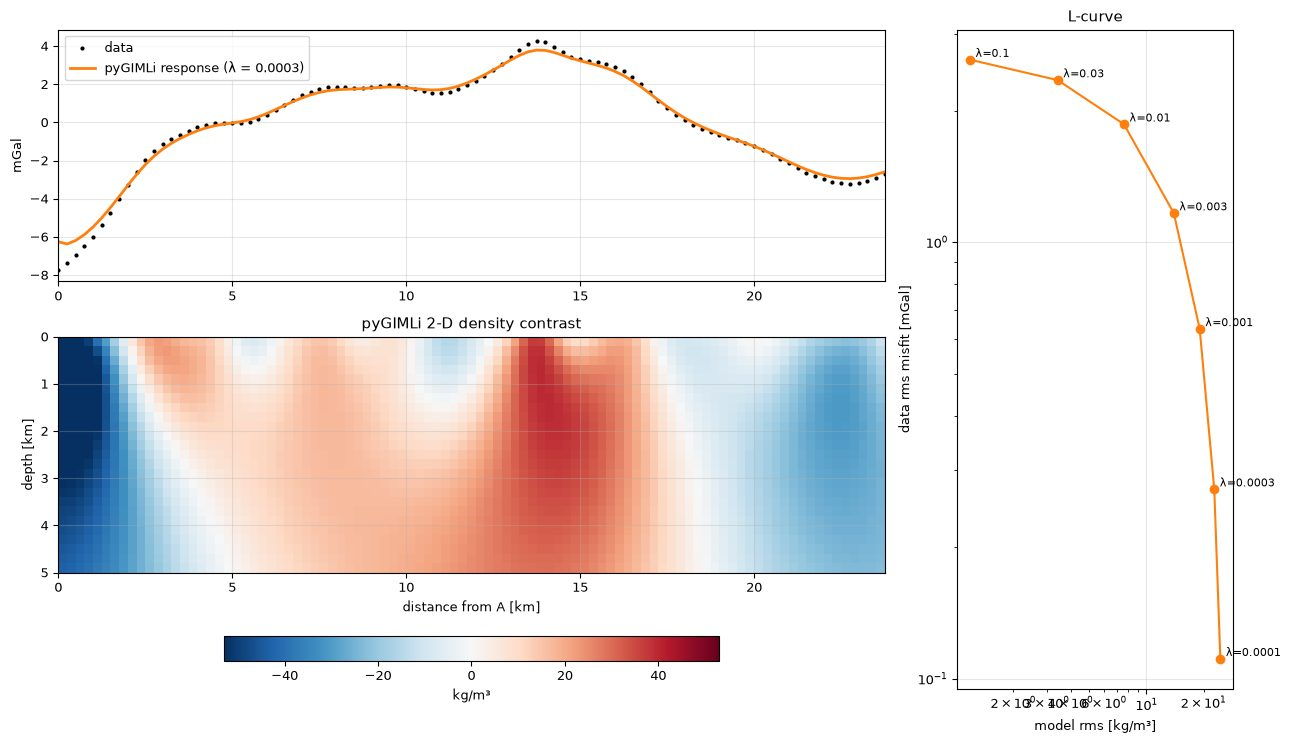

In [13]:
# 📊 RESULT
fig = plt.figure(figsize=(13, 7.5))
gs = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[1, 1.4])
ax0 = fig.add_subplot(gs[0, 0])
ax0.plot(x / 1000, d_obs, "k.", ms=4, label="data")
ax0.plot(x / 1000, d_pg, "-", color="C1", lw=2, label=f"pyGIMLi response (λ = {LAMBDA:g})")
ax0.set(ylabel="mGal", xlim=(x.min() / 1000, x.max() / 1000)); ax0.legend()
ax1 = fig.add_subplot(gs[1, 0], sharex=ax0)
lim = np.nanpercentile(np.abs(rho_pg), 98)
pc = ax1.pcolormesh(xe / 1000, Z_EDGES_M / 1000, rho_pg.reshape(len(Z_EDGES_M) - 1, len(xe) - 1)[::-1], cmap=DENS_CMAP,
                    vmin=-lim, vmax=lim, shading="flat")
ax1.set(ylim=(5, 0), xlabel="distance from A [km]", ylabel="depth [km]", title="pyGIMLi 2-D density contrast")
plt.colorbar(pc, ax=ax1, label="kg/m³", orientation="horizontal", pad=0.18, shrink=0.6)
ax2 = fig.add_subplot(gs[:, 1])
ax2.loglog(lcurve["model_norm"], lcurve["rms_mgal"], "o-", color="C1")
for r in lcurve.itertuples():
    ax2.annotate(f"λ={r.lam:g}", (r.model_norm, r.rms_mgal), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax2.set(xlabel="model rms [kg/m³]", ylabel="data rms misfit [mGal]", title="L-curve")
plt.tight_layout()

## 5  3-D inversion with SimPEG

SimPEG inverts the gridded residual in 3-D on a tensor mesh (`discretize.TensorMesh`), using the integral
formulation with Choclo kernels. Settings:

* **Data:** grid nodes every `DATA_STEP` × 100 m inside the data area, at a constant height of 450 m.
* **Model:** density contrast in g/cm³, limited to `BOUNDS`.
* **Regularisation:** smallness plus smoothness (`WeightedLeastSquares`).
* **Weighting:** sensitivity weighting replaces the depth weighting.
* **Stopping:** β is cooled until the data misfit reaches its target (χ² ≈ number of data).

**Sign:** SimPEG's `gz` is positive upward, so a dense body gives a negative `gz`. The data passed to SimPEG are therefore −Δg.

In [14]:
# ✏️ PARAMETERS – edit and re-run from here
DATA_STEP = 10                         # take every 10th grid node (1 km)
CORE_DX, CORE_DZ, N_LAYERS = 500.0, 250.0, 20
BOUNDS = (-1.0, 1.0)                   # g/cm³
ERROR_MGAL_3D = 0.10

In [15]:
# ▶ PROCESSING
sub = grids.isel(easting=slice(0, None, DATA_STEP), northing=slice(0, None, DATA_STEP))
GE, GN = np.meshgrid(sub.easting.values, sub.northing.values)
ok = sub["data_mask"].values & np.isfinite(sub[FIELD].values)
g3 = sub[FIELD].values[ok] - np.mean(sub[FIELD].values[ok])
rx_xyz = np.column_stack([GE[ok], GN[ok], np.full(ok.sum(), 450.0)])
span_x, span_y = GE[ok].max() - GE[ok].min() + 6000, GN[ok].max() - GN[ok].min() + 6000
mesh3d = TensorMesh([[(1000, 6, -1.4), (CORE_DX, int(span_x / CORE_DX)), (1000, 6, 1.4)],
                     [(1000, 6, -1.4), (CORE_DX, int(span_y / CORE_DX)), (1000, 6, 1.4)],
                     [(1000, 4, -1.4), (CORE_DZ, N_LAYERS)]], origin="CCN")
mesh3d.origin = mesh3d.origin + np.r_[(GE[ok].min() + GE[ok].max()) / 2, (GN[ok].min() + GN[ok].max()) / 2, 0.0]
rx = gravity.receivers.Point(rx_xyz, components="gz")
survey = gravity.survey.Survey(gravity.sources.SourceField(receiver_list=[rx]))
obs = data.Data(survey, dobs=-g3, standard_deviation=np.full_like(g3, ERROR_MGAL_3D))   # SimPEG gz is positive up
mmap = maps.IdentityMap(nP=mesh3d.n_cells)
sim = gravity.simulation.Simulation3DIntegral(survey=survey, mesh=mesh3d, rhoMap=mmap, engine="choclo",
                                              store_sensitivities="ram")
dmis = data_misfit.L2DataMisfit(data=obs, simulation=sim)
reg = regularization.WeightedLeastSquares(mesh3d, mapping=mmap)
opt = optimization.ProjectedGNCG(maxIter=15, lower=BOUNDS[0], upper=BOUNDS[1], maxIterLS=20, cg_maxiter=30, cg_rtol=1e-3)
problem = inverse_problem.BaseInvProblem(dmis, reg, opt)
dirs = [directives.UpdateSensitivityWeights(every_iteration=False), directives.BetaEstimate_ByEig(beta0_ratio=10),
        directives.BetaSchedule(coolingFactor=5, coolingRate=1), directives.UpdatePreconditioner(),
        directives.TargetMisfit(chifact=1)]
tic = time.time()
rho_3d = inversion.BaseInversion(problem, directiveList=dirs).run(np.zeros(mesh3d.n_cells))
pred3 = -sim.dpred(rho_3d)
sp_seconds = time.time() - tic
print(f"SimPEG: {len(g3)} data, {mesh3d.n_cells} cells {mesh3d.shape_cells}, {time.time() - tic:.0f} s; "
      f"rms misfit {np.sqrt(np.mean((pred3 - g3) ** 2)):.3f} mGal; density {rho_3d.min():.3f} … {rho_3d.max():.3f} g/cm³")


Running inversion with SimPEG v0.25.2


================================================= Projected GNCG =================================================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS   iter_CG   CG |Ax-b|/|b|  CG |Ax-b|   Comment   
-----------------------------------------------------------------------------------------------------------------
   0  1.48e-02  3.95e+05  0.00e+00  3.95e+05                         0           inf          inf                


   1  1.48e-02  3.43e+05  1.67e+06  3.67e+05    3.45e+02      0      8        6.04e-04     1.14e+02              


   2  2.97e-03  2.24e+05  2.35e+07  2.93e+05    3.43e+02      0      9        3.53e-04     4.84e+01              


   3  5.93e-04  8.12e+04  1.36e+08  1.62e+05    3.40e+02      0      10       8.79e-04     9.01e+01              


   4  1.19e-04  1.95e+04  3.56e+08  6.18e+04    3.34e+02      0      14       9.33e-04     4.59e+01              


   5  2.37e-05  3.51e+03  6.28e+08  1.84e+04    3.20e+02      0      26       7.58e-04     1.24e+01              


   6  4.75e-06  5.92e+02  8.70e+08  4.72e+03    2.93e+02      0      30       1.36e-02     6.29e+01              


   7  9.50e-07  8.64e+01  1.08e+09  1.11e+03    2.37e+02      0      30       1.76e-01     2.09e+02              
------------------------- STOP! -------------------------
1 : |fc-fOld| = 3.0733e+02 <= tolF*(1+|f0|) = 3.9468e+04
0 : |xc-x_last| = 9.0338e-01 <= tolX*(1+|x0|) = 1.0000e-01
0 : |proj(x-g)-x|    = 2.3652e+02 <= tolG          = 1.0000e-01
0 : |proj(x-g)-x|    = 2.3652e+02 <= 1e3*eps       = 1.0000e-02
0 : maxIter   =      15    <= iter          =      7
------------------------- DONE! -------------------------
SimPEG: 404 data, 120048 cells (82, 61, 24), 8 s; rms misfit 0.046 mGal; density -0.170 … 0.243 g/cm³


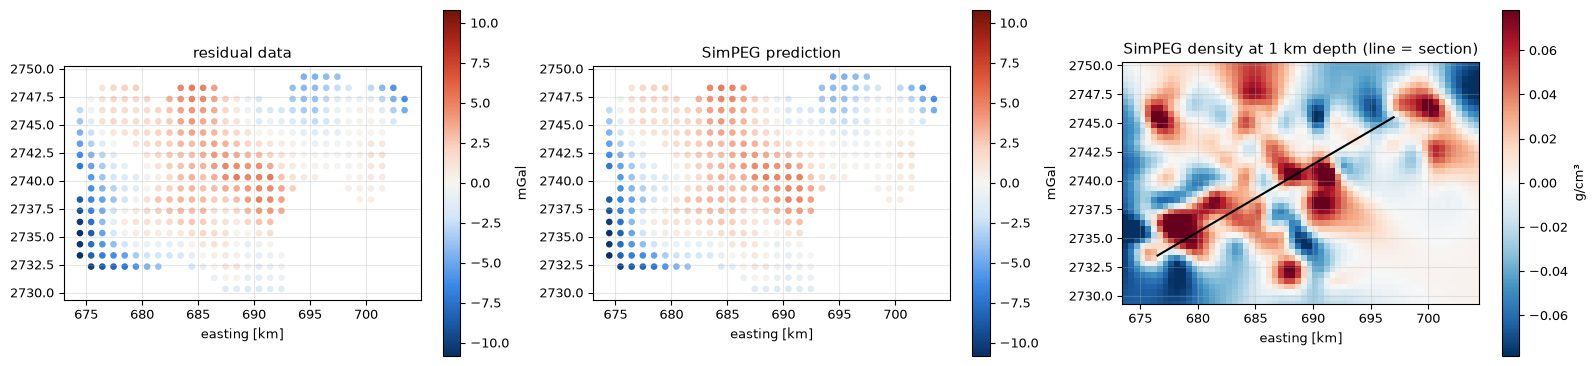

In [16]:
# 📊 RESULT
from scipy.interpolate import RegularGridInterpolator
M3 = rho_3d.reshape(mesh3d.shape_cells, order="F")
interp3 = RegularGridInterpolator((mesh3d.cell_centers_x, mesh3d.cell_centers_y, mesh3d.cell_centers_z), M3,
                                  bounds_error=False, fill_value=np.nan)
zc = mesh3d.cell_centers_z[mesh3d.cell_centers_z > -5000]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, v, title in ((axes[0], g3, "residual data"), (axes[1], pred3, "SimPEG prediction")):
    sc = ax.scatter(rx_xyz[:, 0] / 1000, rx_xyz[:, 1] / 1000, c=v, s=14, cmap=mapping.ANOM, vmin=-np.abs(g3).max(), vmax=np.abs(g3).max())
    ax.set(aspect="equal", title=title, xlabel="easting [km]"); plt.colorbar(sc, ax=ax, shrink=0.8, label="mGal")
zs = -1000.0
gx, gy = np.meshgrid(mesh3d.cell_centers_x, mesh3d.cell_centers_y)
sl = interp3(np.column_stack([gx.ravel(), gy.ravel(), np.full(gx.size, zs)])).reshape(gx.shape)
lim = np.nanpercentile(np.abs(rho_3d), 99)
pc = axes[2].pcolormesh(gx / 1000, gy / 1000, sl, cmap=DENS_CMAP, vmin=-lim, vmax=lim, shading="auto")
axes[2].plot([ea / 1000, eb / 1000], [na / 1000, nb / 1000], "k-", lw=1.5)
axes[2].set(aspect="equal", title="SimPEG density at 1 km depth (line = section)", xlabel="easting [km]",
            xlim=(GE[ok].min() / 1000 - 1, GE[ok].max() / 1000 + 1), ylim=(GN[ok].min() / 1000 - 1, GN[ok].max() / 1000 + 1))
plt.colorbar(pc, ax=axes[2], shrink=0.8, label="g/cm³")
plt.tight_layout()

## 6  The two models along the section

The SimPEG 3-D model is cut along A–B and shown under the pyGIMLi 2-D model, with both data fits. The two methods
differ in dimension (2-D against 3-D), weighting and regularisation. Features that appear in both are better
supported by the data than features that appear in only one.

In [17]:
# ▶ PROCESSING
XX, ZZ = np.meshgrid(x, -zc)
ee = np.interp(XX, dist, pe); nn = np.interp(XX, dist, pn)
sec3 = interp3(np.column_stack([ee.ravel(), nn.ravel(), -ZZ.ravel()])).reshape(XX.shape) * 1000      # kg/m³
pred_grid = np.full(GE.shape, np.nan); pred_grid[ok] = pred3
d3_sec = RegularGridInterpolator((sub.northing.values, sub.easting.values), pred_grid, bounds_error=False)(np.column_stack([pn[keep], pe[keep]]))
print(f"SimPEG section density {np.nanmin(sec3):.0f} … {np.nanmax(sec3):.0f} kg/m³")

SimPEG section density -43 … 167 kg/m³


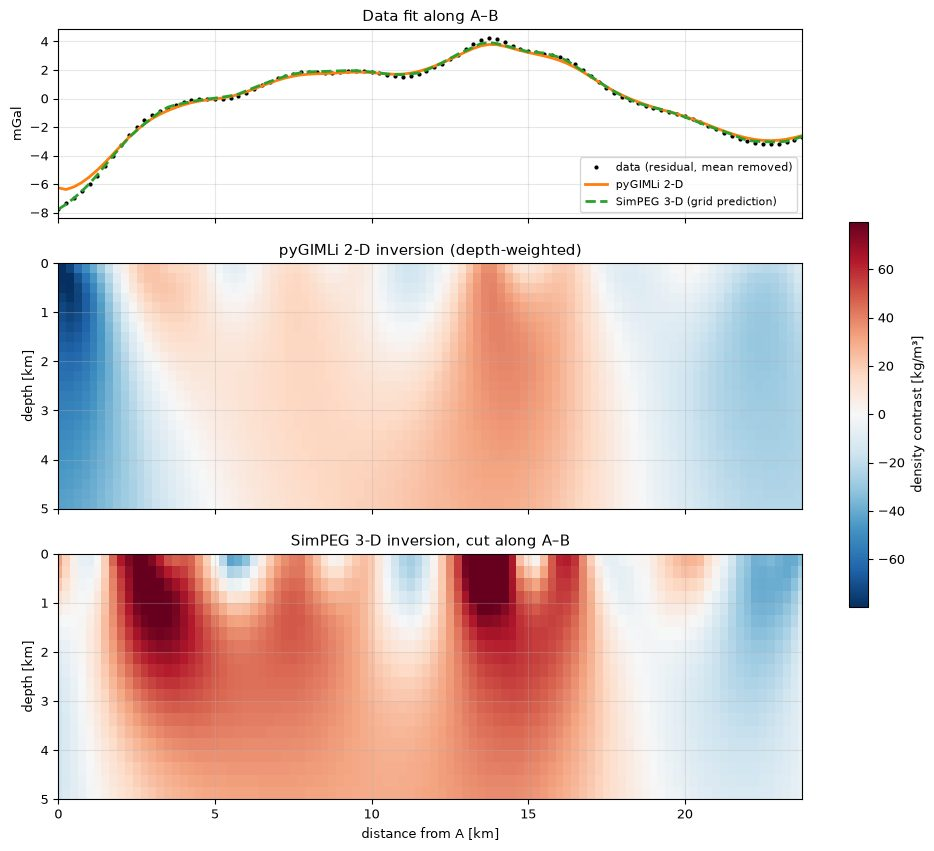

In [18]:
# 📊 RESULT
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1.3, 1.3]})
axes[0].plot(x / 1000, d_obs, "k.", ms=4, label="data (residual, mean removed)")
axes[0].plot(x / 1000, d_pg, "-", color="C1", lw=2, label="pyGIMLi 2-D")
axes[0].plot(x / 1000, d3_sec - np.nanmean(d3_sec), "--", color="C2", lw=2, label="SimPEG 3-D (grid prediction)")
axes[0].set(ylabel="mGal", title="Data fit along A–B"); axes[0].legend(fontsize=8)
lim = max(np.nanpercentile(np.abs(rho_pg), 98), np.nanpercentile(np.abs(sec3), 98))
pc = axes[1].pcolormesh(xe / 1000, Z_EDGES_M / 1000, rho_pg.reshape(len(Z_EDGES_M) - 1, len(xe) - 1)[::-1], cmap=DENS_CMAP,
                        vmin=-lim, vmax=lim, shading="flat")
axes[1].set(ylim=(5, 0), ylabel="depth [km]", title="pyGIMLi 2-D inversion (depth-weighted)", xlim=(x.min() / 1000, x.max() / 1000))
axes[2].pcolormesh(x / 1000, -zc / 1000, sec3, cmap=DENS_CMAP, vmin=-lim, vmax=lim, shading="auto")
axes[2].set(ylim=(5, 0), xlabel="distance from A [km]", ylabel="depth [km]", title="SimPEG 3-D inversion, cut along A–B")
for ax in axes[1:]:
    ax.plot(x / 1000, np.zeros_like(x), "k-", lw=0.5)
fig.colorbar(pc, ax=axes, label="density contrast [kg/m³]", shrink=0.5)
fig.savefig(os.path.join(OUT_DIR, "section_models.png"), dpi=200, bbox_inches="tight")

## 7  Export

Writes `section_profile.csv` (points, topography, data and both model responses), the two section models as CSV
(distance, depth, density) and the SimPEG 3-D model as a NumPy archive with its mesh, all to `outputs/modelling/`.

In [19]:
# ▶ PROCESSING
section["pygimli_response_mGal"] = d_pg
section["simpeg_response_mGal"] = d3_sec - np.nanmean(d3_sec)
section["forward_model_mGal"] = d_fwd
hdr = "# Wadi Ghadir section A-B, written by Mohamed Sobh, LIAG. Field: " + FIELD + "\n"
with open(os.path.join(OUT_DIR, "section_profile.csv"), "w") as fh:
    fh.write(hdr); section.to_csv(fh, index=False, float_format="%.6f")
cxz = np.array([[c.center().x(), -c.center().y()] for c in mesh2d.cells()])
pd.DataFrame({"distance_m": cxz[:, 0], "depth_m": cxz[:, 1], "density_kgm3": rho_pg}).to_csv(
    os.path.join(OUT_DIR, "pygimli_section_model.csv"), index=False, float_format="%.3f")
pd.DataFrame({"distance_m": XX.ravel(), "depth_m": ZZ.ravel(), "density_kgm3": sec3.ravel()}).dropna().to_csv(
    os.path.join(OUT_DIR, "simpeg_section_model.csv"), index=False, float_format="%.3f")
np.savez_compressed(os.path.join(OUT_DIR, "simpeg_3d_model.npz"), density_gcc=rho_3d, hx=mesh3d.h[0], hy=mesh3d.h[1],
                    hz=mesh3d.h[2], origin=mesh3d.origin, data_xyz=rx_xyz, data_mGal=g3, predicted_mGal=pred3)
summary = {"written_by": "Mohamed Sobh, LIAG", "field": FIELD, "A_lonlat": A_LONLAT, "B_lonlat": B_LONLAT,
           "length_m": float(L), "spacing_m": float(SAMPLE_M),
           "pygimli": {"lambda": float(LAMBDA), "chi2": float(chi2_pg), "error_mGal": ERROR_MGAL, "cells": mesh2d.cellCount(),
                       "rms_mGal": float(np.sqrt(np.mean((d_pg - d_obs) ** 2))), "ctype": CTYPE,
                       "depth_weighting": {"z0_m": DW_Z0_M, "power": DW_POWER}},
           "simpeg": {"data": int(len(g3)), "cells": int(mesh3d.n_cells), "seconds": round(sp_seconds, 1),
                      "rms_mGal": float(np.sqrt(np.mean((pred3 - g3) ** 2))), "bounds_gcc": list(BOUNDS)},
           "forward": {"bodies": BODIES, "rms_mGal": float(np.sqrt(np.mean((d_fwd - d_obs) ** 2)))}}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=1)
sorted(os.listdir(OUT_DIR))

['pygimli_section_model.csv',
 'section_models.png',
 'section_profile.csv',
 'simpeg_3d_model.npz',
 'simpeg_section_model.csv',
 'summary.json']

---
### References

* Rücker, C., Günther, T. & Wagner, F. M. (2017). pyGIMLi: An open-source library for modelling and inversion in geophysics. *Computers & Geosciences* 109.
* Cockett, R. et al. (2015). SimPEG: An open source framework for simulation and gradient based parameter estimation in geophysical applications. *Computers & Geosciences* 85.
* Li, Y. & Oldenburg, D. W. (1998). 3-D inversion of gravity data. *Geophysics* 63.
* Talwani, M., Worzel, J. L. & Landisman, M. (1959). Rapid gravity computations for two-dimensional bodies. *JGR* 64.

*Written by Mohamed Sobh, LIAG.*